In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

In [1]:
prefix = '/mnt/staging/' # or
# prefix = '/scratch/' #for s1n3/4
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"


fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"

figure_config_root = str(PREPARES / "config") + "/"
epochs_rest_root = str(PREPARES / "epochs-rest") + "/"

mouse='cm229'

In [4]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]

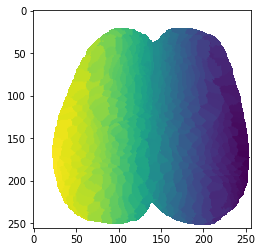

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [6]:
mouse_id = mouse
   
M2_ind = load_pickle(fetch_path_motor+'brightest_frontline_ind-'+mouse_id)
sensory_ind = load_pickle(fetch_path_sensory+'brightest_ind_'+mouse_id)

extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse_id)
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse_id)

# sensory_ind['RV']=extra_extra_ind['RV']
# sensory_ind['LV']=extra_extra_ind['LV']
sensory_ind['LV']=106
sensory_ind['RV']=415

M1_ind_from_coherence = load_pickle(fetch_path_M1+'M1_ind_'+mouse)

sensory_ind['LW']=54
sensory_ind['RW']=464
sensory_ind['RRSP']= 310 # cm229
sensory_ind['LRSP']= 211 # cm229
sensory_ind['LALM']=extra_ind['ALM']
sensory_ind['RALM']=447
sensory_ind['RFP_M1_extra']=440 # cm229
sensory_ind['LFP_M1_extra']=79 # cm229
sensory_ind['RholeMOp']=381 # cm229
sensory_ind['LholeMOp']=119 # cm229
sensory_ind['RT']=sensory_ind['tail'] # cm229
sensory_ind['LT']=139
sensory_ind['Rposterior']=418 # cm229
sensory_ind['Lposterior']=80 # cm229

In [7]:
load_full_corr_map_path = str(PREPARES / "heterogeneity/all-seed") + "/"
all_corr_maps = []
f_h5_corr =  h5py.File(load_full_corr_map_path+mouse+'_all_corr_maps_dict.h5', "r")
for i in range(500):
    all_corr_maps.append(np.array(f_h5_corr['roi_'+str(i)])[:,:,np.newaxis])

all_corr_maps = np.concatenate(all_corr_maps,axis=2)

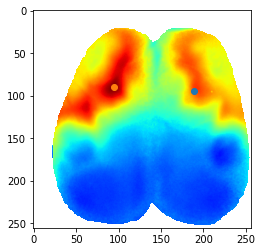

In [8]:
plt.imshow(all_corr_maps[:,:,381],vmin=0,vmax=1,cmap='jet')
plt.scatter(node_coords[119,1],node_coords[119,0])
plt.scatter(node_coords[381,1],node_coords[381,0])
# plt.scatter(node_coords[sensory_ind['LFP'],1],node_coords[sensory_ind['LFP'],0])

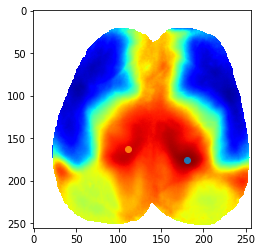

In [9]:
plt.imshow(all_corr_maps[:,:,139],vmin=0,vmax=1,cmap='jet')
plt.scatter(node_coords[139,1],node_coords[139,0])
plt.scatter(node_coords[342,1],node_coords[342,0])

In [ ]:
load_full_corr_map_path = str(PREPARES / "heterogeneity") + "/"
all_corr_maps = []
f_h5_corr =  h5py.File(load_full_corr_map_path+mouse+'_all_corr_maps_dict.h5', "r")
for i in range(500):
    all_corr_maps.append(np.array(f_h5_corr['roi_'+str(i)])[:,:,np.newaxis])

all_corr_maps = np.concatenate(all_corr_maps,axis=2)

# load full rest data

In [10]:
load_filename = fetch_path_M1+'final_'+mouse+'_MM_jrgeco_'+mouse
hf = h5py.File(load_filename, 'r')
MM_jrgeco_REST = np.array(hf.get('MM_jrgeco_REST'))
hf.close()






In [11]:
MM_jrgeco_REST.shape

(256, 256, 600, 102)

In [12]:
H_rest = getH_4D(MM_jrgeco_REST,IDX_sorted)

In [13]:
H_rest.shape

(500, 600, 102)

**get rid of midline**

In [14]:
with h5py.File(figure_config_root+'mask_midline_v2_'+mouse+'.mat','r') as f_midline:
        mask_midline = np.array(f_midline['mask_midline']).T

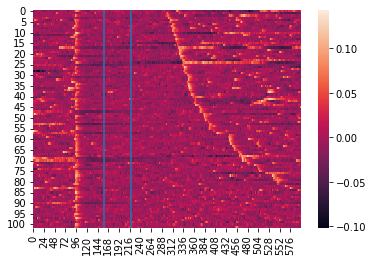

In [15]:
T_PRE_REST = 160
T_STOP_REST = 220
sns.heatmap(H_rest[sensory_ind['RHP'],:,:].T)
plt.axvline(T_PRE_REST);plt.axvline(T_STOP_REST)

In [16]:
concat_jrgeco_full_rest = MM_jrgeco_REST[:,:,T_PRE_REST:T_STOP_REST,:]
ss = concat_jrgeco_full_rest.shape
concat_jrgeco_full_rest = concat_jrgeco_full_rest.transpose((0,1,3,2)).reshape((256,256,ss[2]*ss[3]))




In [17]:
concat_jrgeco_full_rest.shape

(256, 256, 6120)

In [18]:
concat_jrgeco_full_rest  = np.multiply(concat_jrgeco_full_rest,np.repeat(mask_midline[:,:,np.newaxis],
                            repeats=concat_jrgeco_full_rest.shape[-1],axis=2))

In [19]:
concat_H = getH(concat_jrgeco_full_rest,IDX_sorted)

/home/wx2203/Weihao/code_locker/common_functions/f2_utils.py:17: RuntimeWarning: Mean of empty slice
  H[i_H,:]=np.nanmean(data_reshape[temp==True,:],axis=0)


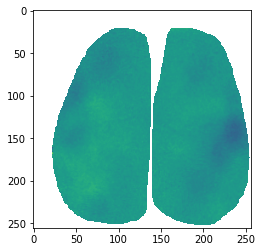

In [20]:
plt.imshow(concat_jrgeco_full_rest[:,:,120])

In [20]:
# OG:
# M2_ind['LHP']= M2_ind_from_coherence['LHP']
# M2_ind['RHP']= M2_ind_from_coherence['RHP']

In [21]:
# use ROI version of HP
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]



In [22]:
# concatenate
all_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT','LFP', 'LHP',  'LW', 'LM', 'LN','LT']
all_bdps_list_M2 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RV','LFP', 'LHP',  'LW', 'LM', 'LN','LV']
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP']
all_bdps_extra = ['RALM','LALM', 'RV', 'LV','RRSP','LRSP','RFP_M1_extra','LFP_M1_extra', 
                 'RholeMOp','LholeMOp','Rposterior','Lposterior']
all_bdps_S1 = [bdp+'_S1' for bdp in all_bdps_list_S1]
all_bdps_M2 = [bdp+'_M2' for bdp in all_bdps_list_M2]
all_bdps_M1 = [bdp+'_M1' for bdp in all_bdps_list_M1]

all_bdps = all_bdps_extra + all_bdps_M2 + all_bdps_S1 + all_bdps_M1


TCs_matrix = np.empty((0,concat_H.shape[1]))

for i_key,key in enumerate(all_bdps_extra):
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[sensory_ind[key],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M2):
    bdp = key.split('_M2')[0]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    small_roi_tcs = np.nanmean(np.nanmean(
concat_jrgeco_full_rest[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    TCs_matrix = np.append(TCs_matrix,
                           small_roi_tcs[np.newaxis,:],
                           axis=0)

for i_key,key in enumerate(all_bdps_S1):
    bdp = key.split('_S1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[sensory_ind[bdp],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M1):
    bdp = key.split('_M1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[M1_ind_from_coherence[bdp],np.newaxis,:],
                           axis=0)
    
# index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
# median_TCs_matrix = np.median(TCs_matrix[index_M2s+[0,1],:],axis=0)


# TCs_matrix[index_M2s+[0,1],:] = TCs_matrix[index_M2s+[0,1],:] - 5*median_TCs_matrix[np.newaxis,:]/len(index_M2s+[0,1]) 
# median_TCs_matrix = median_TCs_matrix#*len(index_M2s+[0]) 

# TCs_matrix = np.append(TCs_matrix,median_TCs_matrix[np.newaxis,:],axis=0)

# TCs_matrix = np.append(TCs_matrix,np.ones((1,concat_H.shape[1])),axis=0)



/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:28: RuntimeWarning: Mean of empty slice


In [23]:
MM_jrgeco_reshape = concat_jrgeco_full_rest.reshape((256*256,-1))

# quick test on NNLS

In [24]:
total_T = TCs_matrix.shape[1]
to_cut = total_T % 4
if to_cut != 0 :
    TCs_matrix = TCs_matrix[:,:-to_cut]
    MM_jrgeco_reshape = MM_jrgeco_reshape[:,:-to_cut]
total_T = total_T - to_cut

In [25]:
dict_ind ={}
split_size = int(total_T/4)
for fold_k in range(4):
    dict_ind[fold_k] = np.arange(split_size*fold_k,split_size*(fold_k+1))
    

In [26]:
import numpy as np
from scipy.optimize import minimize
from scipy.sparse import csr_matrix

def nnls_optimization(A, b):
    """
    Solves the Non-Negative Least Squares (NNLS) problem using constrained optimization.

    Parameters:
    A (numpy.ndarray or scipy.sparse.csr_matrix): The input matrix.
    b (numpy.ndarray): The input vector.

    Returns:
    numpy.ndarray: The solution vector x.
    """
    # Check if A is sparse and convert to csr_matrix if it is not
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    # Objective function: 0.5 * ||Ax - b||^2
    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual)**2

    # Gradient of the objective function
    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    # Initial guess (zeros)
    x0 = np.zeros(A.shape[1])

    # Bounds: 0 <= x
    bounds = [(0, None) for _ in range(A.shape[1])]

    # Optimize using 'L-BFGS-B' method for bound-constrained problems
    result = minimize(objective, x0, method='SLSQP', jac=objective_jac, bounds=bounds, options={'disp': False})

    return result.x

# # Example usage
# if __name__ == "__main__":
#     # Example with a larger dataset
#     np.random.seed(0)
#     A = np.random.rand(1000, 500)
#     b = np.random.rand(1000)
    
#     x = nnls_optimization(A, b)
#     print("Solution:", x)


In [27]:
MM_jrgeco_reshape.shape

(65536, 6120)

In [28]:
start = time.time()
temp = Parallel(n_jobs=10)(delayed(nnls_optimization)(np.nan_to_num(TCs_matrix[:,::2].T), 
    np.nan_to_num(MM_jrgeco_reshape[i_region,::2])) for i_region in range(256*256))
full_M = np.vstack(temp)
end = time.time()
print(end - start)

255.8872208595276


In [29]:
mask = concat_jrgeco_full_rest[:,:,100]>-100
mask = mask.astype('float')
mask[mask==0]=np.nan
mask_reshape = mask.reshape((256*256))


W_S1M2M1 = full_M[mask_reshape==1,:]

# add M2 ones
W_S1M2M1_M2 = []
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    W_S1M2M1_M2.append(W_S1M2M1[:,ind_in_list])
W_S1M2M1_M2_sum = np.clip(np.sum(np.stack(W_S1M2M1_M2,0),0), 0, 1)
W_S1M2M1 = np.append(W_S1M2M1,W_S1M2M1_M2_sum[:,np.newaxis],axis=1)
# add cortical ones
W_S1M2M1 = np.append(W_S1M2M1,np.ones((len(W_S1M2M1_M2_sum),1)),axis=1)

W_masked = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked[:]=np.nan
W_masked[mask_reshape==1,:] = W_S1M2M1
W_masked = W_masked.reshape((256,256,-1))




In [30]:
# append median tc 
index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
TCs_matrix=np.append(TCs_matrix,np.median(TCs_matrix[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
# append 1 tc 
TCs_matrix = np.append(TCs_matrix,np.ones((1,TCs_matrix.shape[1])),axis=0)

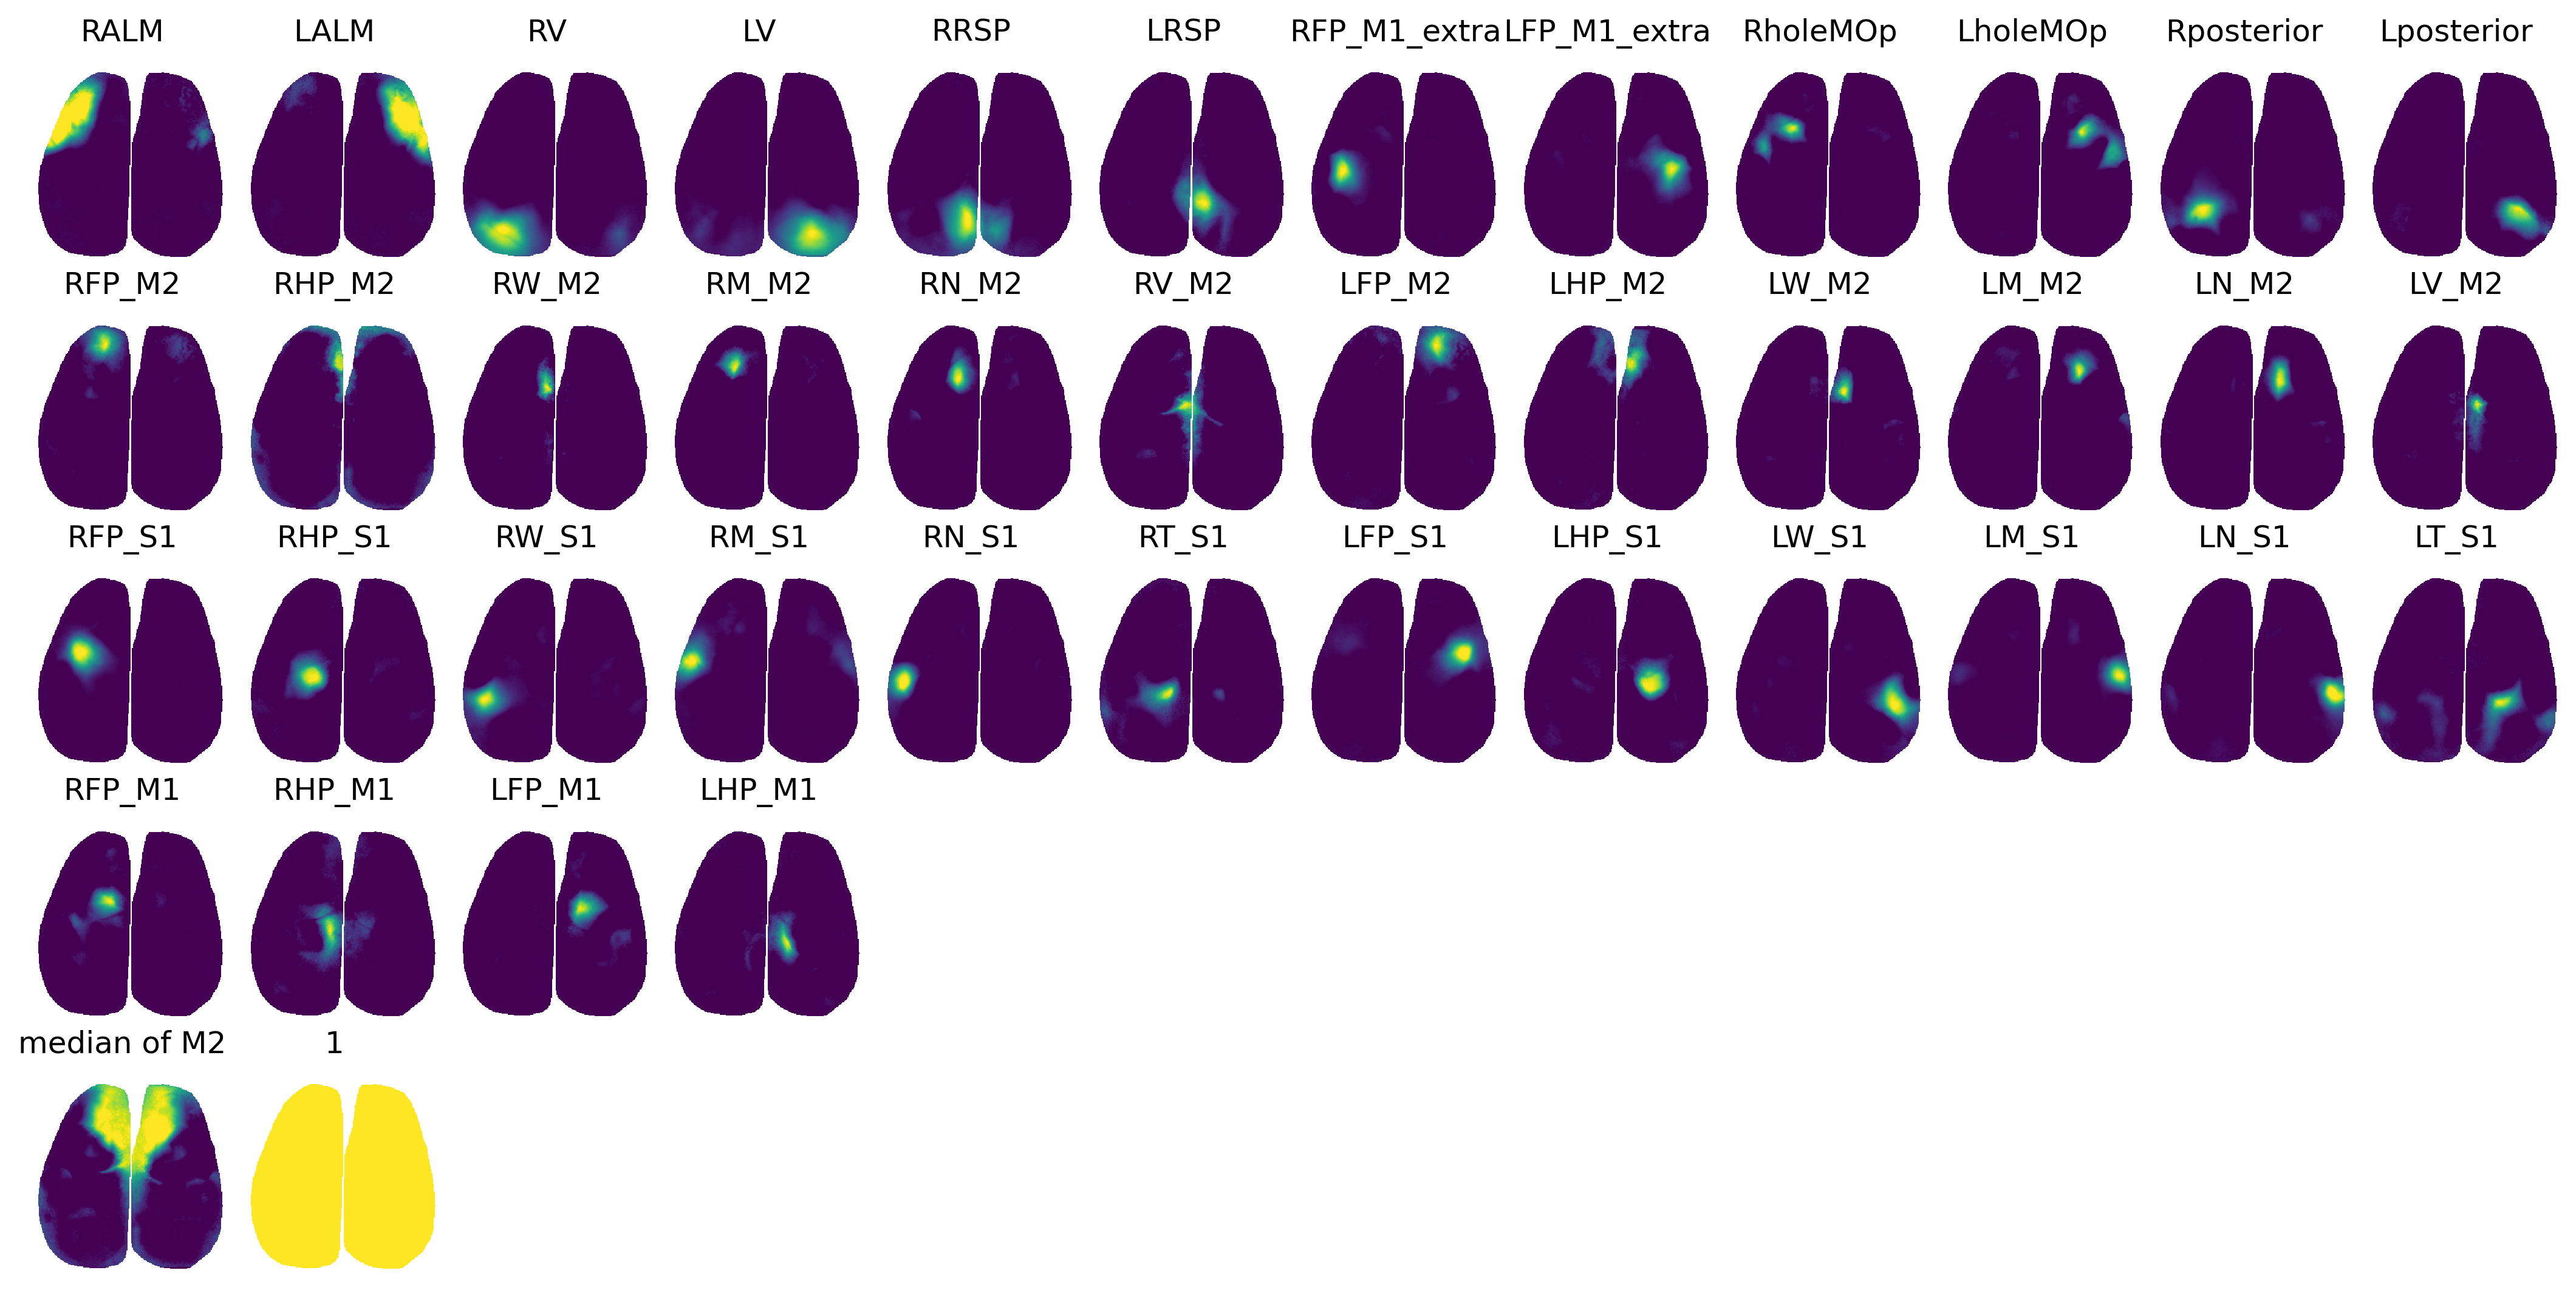

In [31]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+12:y_offset+17,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+18:y_offset+23,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)+2):
    exec("ax{} = fig.add_subplot(gs[y_offset+24:y_offset+29,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5

##########################################
##########################################
for i_key,key in enumerate(all_bdps_extra):
    ind_in_list = all_bdps.index(key)
    W_masked_2show = W_masked[:,:,ind_in_list]        
    exec("ax{}.imshow(W_masked_2show,vmin=0,vmax=1)".format(i_key))
    exec("ax{}.set_title(key)".format(i_key))
    # plt.axis('off')
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_S1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_M1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))

# plot median
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)
exec("ax{}.imshow(W_masked[:,:,-2],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('median of M2')".format(i_entry))

# plot 1
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)+1
exec("ax{}.imshow(W_masked[:,:,-1],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('1')".format(i_entry))

for i_ax in range(50):
    try:
        exec("ax{}.axis('off')".format(i_ax))
    except:
        continue

In [32]:
# plt.imshow(W_masked[:,:,-2],vmin=0,vmax=1)
# ind_here =418
# plt.scatter(node_coords[ind_here,1],node_coords[ind_here,0])
# ind_here =80
# plt.scatter(node_coords[ind_here,1],node_coords[ind_here,0])

# now use the W to fit H

In [33]:
TCs_matrix.shape

(42, 6120)

**now adding constraints**

In [34]:
def nnls_optimization_with_constraints(A, b,x_init,constraints):
    """
    Solves the Non-Negative Least Squares (NNLS) problem using constrained optimization.

    Parameters:
    A (numpy.ndarray or scipy.sparse.csr_matrix): The input matrix.
    b (numpy.ndarray): The input vector.

    Returns:
    numpy.ndarray: The solution vector x.
    """
    # Check if A is sparse and convert to csr_matrix if it is not
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    # Objective function: 0.5 * ||Ax - b||^2
    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual)**2

    # Gradient of the objective function
    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    # Initial guess (zeros)
    x0 = x_init #np.zeros(A.shape[1])
    # x0 = np.zeros(A.shape[1])

    
    result = minimize(objective, x0, method='SLSQP',constraints=constraints,jac=objective_jac, options={'disp': False})

    return result.x


In [35]:
index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
  
def return_constraints(H_ROI,median_here,index_M2s,k):
    # Define the constraints
    constraints = []
    for i_M2 in index_M2s:
        constraints.append({
            'type': 'eq',
            'fun': lambda x, i_M2=i_M2: x[i_M2] - (H_ROI[i_M2] - x[-2])
        })
    constraints.append({'type': 'eq', 'fun': lambda x: x[-2] - k*median_here})  
    # constraints.append({'type': 'ineq', 'fun': lambda x: 0.001 - (np.abs(x[-2] - k*median_here))})  
    
    return constraints


In [36]:
TCs_matrix.shape

(42, 6120)

# Cross validation (4 folds)

# Correlation matrix

In [37]:
num_bdps = len(all_bdps)
dict_corrmaps_4folds={}
for i_fold in range(4):
    ind_here = dict_ind[i_fold]  
    ss = TCs_matrix[:,ind_here].shape
    corr_mat = np.corrcoef(TCs_matrix[:num_bdps,ind_here],TCs_matrix[:num_bdps,ind_here])[:num_bdps,num_bdps:]
    dict_corrmaps_4folds[i_fold] = corr_mat

In [38]:
palatte_dict['RALM'] = palatte_dict['ALM']
palatte_dict['LALM'] = 'bisque'
palatte_dict['RRSP'] = palatte_dict['RSP']
palatte_dict['LRSP'] = 'sandybrown'
palatte_dict['RFP_M1_extra'] = 'tab:olive'
palatte_dict['LFP_M1_extra'] = 'tab:cyan'

palatte_dict['RholeMOp'] = 'tab:green'
palatte_dict['LholeMOp'] = 'tab:orange'

palatte_dict['RT'] = 'tab:brown'
palatte_dict['LT'] = 'goldenrod'

palatte_dict['Rposterior'] = 'palegreen'
palatte_dict['Lposterior'] = 'greenyellow'


dict_all_bdps_for_color = {}
for bdp_name in all_bdps:
    if len(bdp_name.split('_'))==2:
        bdp = bdp_name.split('_')[0]
        dict_all_bdps_for_color[bdp_name] = palatte_dict[bdp]
    else:
        dict_all_bdps_for_color[bdp_name] = palatte_dict[bdp_name]
        
dict_area_color = {'extra':'black','M2':'darkgray','S1':'darkred','M1':'darkgreen'}

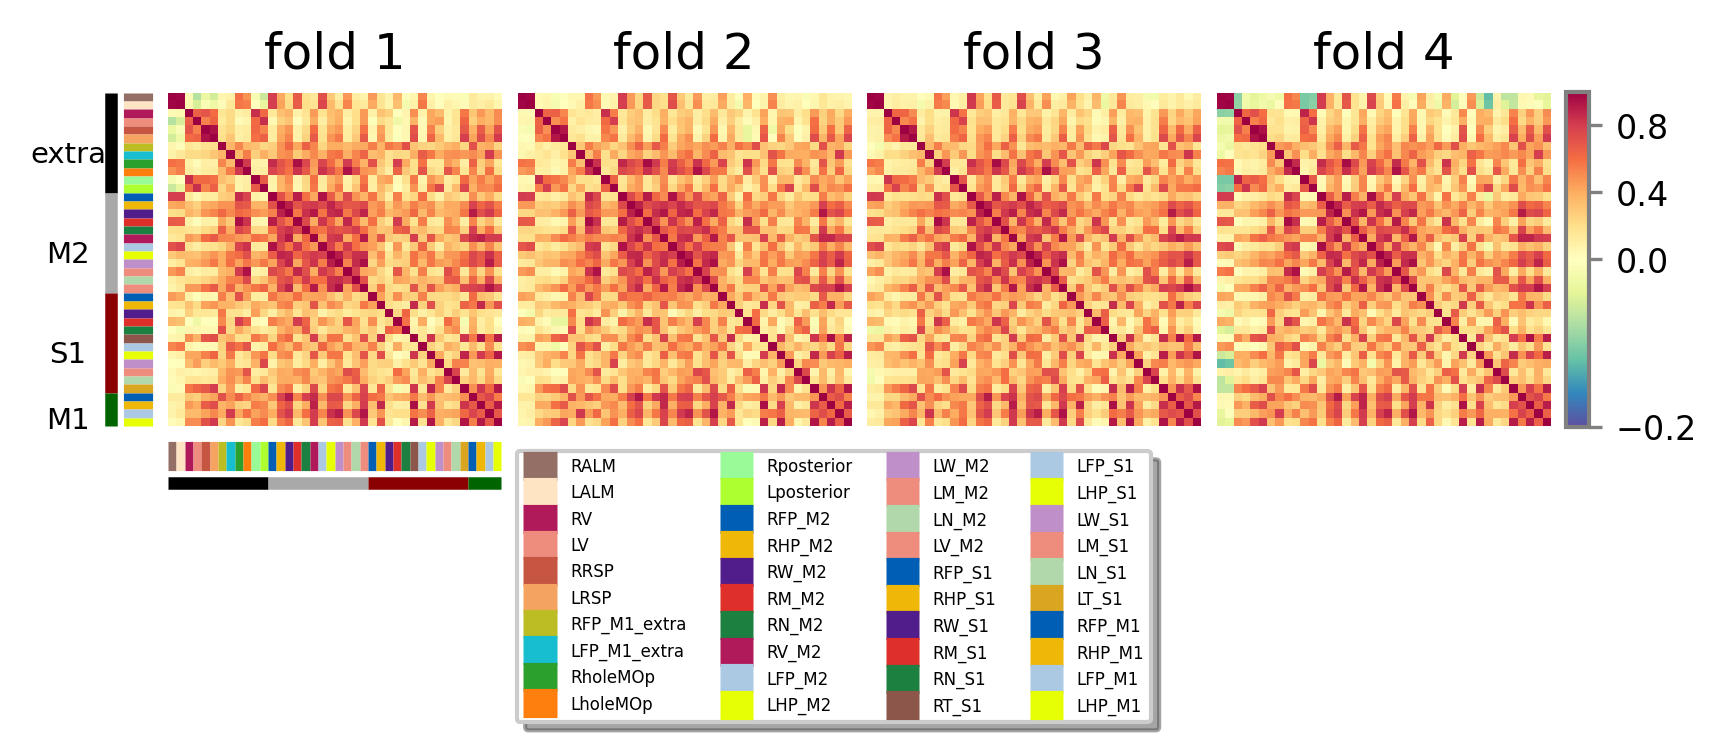

In [39]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5
for i_ax in range(4): # 3 mice S1M1
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.axis('off')".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
ax99 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop-4])
    
divnorm=colors.TwoSlopeNorm(vmin=-0.2, vcenter=0., vmax=1) 
for i_fold in range(4):
    exec("sbp0 = ax{}.imshow(dict_corrmaps_4folds[i_fold] ,cmap='Spectral_r',norm=divnorm)".format(i_fold))
    


cb = fig.colorbar(sbp0, ticks=[-0.2,0,0.4,0.8],cax=ax99,orientation='vertical')
cb.ax.tick_params(labelsize=8,length=3,color='gray')
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
ax99.set_aspect(15)
ax99.set_anchor('W')
# ax0.axis('off')


i_ax=0
exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))
start=-0.5;
for bdp in all_bdps:
    stop = start + 1
    ax2.plot([start,stop],[-0.09,-0.09], color=dict_all_bdps_for_color[bdp],
            transform=trans_x,linewidth=7, clip_on=False,solid_capstyle='butt',label=bdp)
    ax2.plot([-.09,-.09],[start,stop], color=dict_all_bdps_for_color[bdp],
            transform=trans_y,linewidth=7, clip_on=False,solid_capstyle='butt')
    # ax2.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    # if i_ax_temp == 0:
    #     ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")
    start = stop
    
ax2.legend(loc='upper center', bbox_to_anchor=(-0.1, -.05),
          ncol=4, fontsize=4,fancybox=True, shadow=True)


start=-0.5;  
# segregate area (extra, M2, S1, M1)
for i_area,area in enumerate(['all_bdps_extra' ,'all_bdps_M2', 'all_bdps_S1', 'all_bdps_M1']):
    exec("stop = start + len({})".format(area))
    ax2.plot([start,stop],[-0.17,-0.17], color=dict_area_color[area.split('_')[-1]],
            transform=trans_x,linewidth=3, clip_on=False,solid_capstyle='butt')
    ax2.plot([-.17,-.17],[start,stop], color=dict_area_color[area.split('_')[-1]],
            transform=trans_y,linewidth=3, clip_on=False,solid_capstyle='butt')
    ax2.annotate(area.split('_')[-1], xy=(-.3,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")

    start = stop
plt.subplots_adjust(wspace=0.3)

for i_fold in range(4):
    exec("ax{}.set_title('fold {}')".format(i_fold,i_fold+1))
         
         
plt.savefig('fig-SE-corr-maps-4folds.svg',format='svg',dpi=300)

# disentangle M2

In [114]:
dict_score_corr = {}
dict_optimal_k = {}
ks = np.linspace(0,1,30)
for i_fold in range(4):
    
    ind_here = dict_ind[i_fold]
    mask_rest_ind = np.ones(total_T)
    mask_rest_ind[ind_here] = 0
    mask_rest_ind = mask_rest_ind.astype(bool)
    
    
    index_M2s_L = [idx for idx, s in enumerate(all_bdps) if np.logical_and('_M2' in s,'L' in s)]
    index_M2s_R = [idx for idx, s in enumerate(all_bdps) if np.logical_and('_M2' in s,'R' in s)]
    index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
        
    # medianM2_TCs_matrix_L = np.median(TCs_matrix[index_M2s_L,:],axis=0)[np.newaxis,:]
    # medianM2_TCs_matrix_R = np.median(TCs_matrix[index_M2s_R,:],axis=0)[np.newaxis,:]
    # medianM2_TCs_matrix = np.median(TCs_matrix[index_M2s,:],axis=0)[np.newaxis,:]


    
    score_corr = []
    for k in ks:
        
        X = MM_jrgeco_reshape[mask_reshape==1,:][:,mask_rest_ind]
        H_ROI = TCs_matrix[:,mask_rest_ind]
        # H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
        median_M2_tc = np.median(H_ROI[index_M2s,:],0)

        start = time.time()
        temp = Parallel(n_jobs=30)(delayed(nnls_optimization_with_constraints)(
            W_S1M2M1, 
            X[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],
            median_M2_tc[i_t],index_M2s,k)) for i_t in range(X.shape[1]))
        H_fitted = np.vstack(temp).T
        end = time.time()
        print(end - start)
        
        H_fitted_L = H_fitted[:,~np.isnan(H_fitted[0,:])].copy()[index_M2s_L,:]
        H_fitted_R = H_fitted[:,~np.isnan(H_fitted[0,:])].copy()[index_M2s_R,:]
        
        ss = H_fitted_L.shape
        corr_mat_L = np.abs(np.corrcoef(H_fitted_L,
                               H_fitted_L)[:ss[0],ss[0]:])     
        ss = H_fitted_R.shape
        corr_mat_R = np.abs(np.corrcoef(H_fitted_R,
                               H_fitted_R)[:ss[0],ss[0]:])  
        
        off_diagonal_entries_L = corr_mat_L[np.triu_indices(ss[0], k = 1)]
        off_diagonal_entries_R = corr_mat_R[np.triu_indices(ss[0], k = 1)]

        score_corr.append((np.mean(off_diagonal_entries_L) + np.mean(off_diagonal_entries_R))/2 )
    
    dict_score_corr[i_fold] = score_corr
    dict_optimal_k[i_fold] = ks[np.argmin(score_corr)]

510.2361297607422
498.4447658061981
496.6624026298523
486.06093406677246
507.3799674510956
495.8198962211609


/home/wx2203/anaconda3/lib/python3.7/site-packages/joblib/externals/loky/process_executor.py:691: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning


507.66317534446716
492.89024448394775
489.58094596862793


/home/wx2203/anaconda3/lib/python3.7/site-packages/joblib/externals/loky/process_executor.py:691: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning


479.5119173526764
516.4187648296356


...

420.00119805336
422.06949758529663


/home/wx2203/anaconda3/lib/python3.7/site-packages/joblib/externals/loky/process_executor.py:691: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning


421.16888308525085
418.9316680431366
422.0072932243347


/home/wx2203/anaconda3/lib/python3.7/site-packages/joblib/externals/loky/process_executor.py:691: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning


422.1139452457428
422.76058316230774
425.0538959503174
421.62797808647156


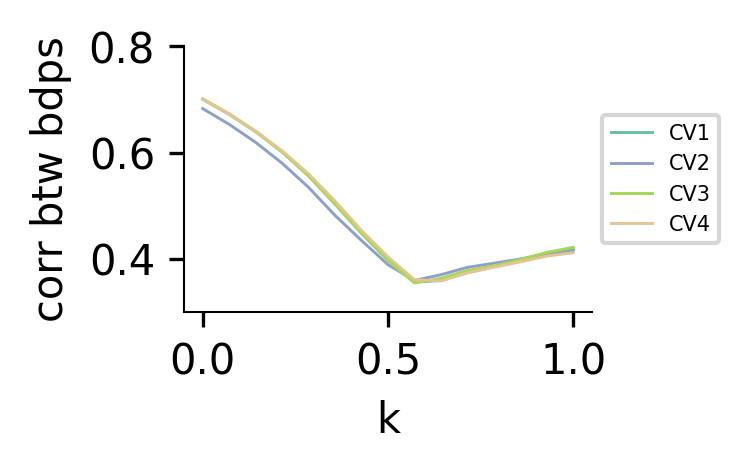

In [11]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+4
x_start = x_offset; x_stop = x_start+6

i_ax = 0
exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    
temp_colors = sns.color_palette("Set2")
for i_fold in range(4):
    ax0.plot(ks,dict_score_corr[i_fold],color=temp_colors[i_fold*2],
             label='CV'+str(i_fold+1),linewidth=0.7)
ax0.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=5)
ax0.set_ylabel('corr btw bdps')
ax0.set_xlabel('k')
ax0.set_ylim([0.3,0.8])
for axis in ['top','right','left','bottom']:
    for i_ax in range(0,1):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue
for axis in ['top','right']:
    ax0.spines[axis].set_linewidth(0)
    
plt.savefig('fig-SE-corr-against-k.svg',format='svg',dpi=300)

In [20]:
CLS_root = str(PREPARES / "CLS") + "/"
dict_results_corr = {'dict_score_corr':dict_score_corr,
                    'dict_optimal_k':dict_optimal_k,
                    'ks':ks}
with open(CLS_root+'dict_results_corr_'+mouse, "wb") as f:
    pickle.dump(dict_results_corr, f, protocol=pickle.HIGHEST_PROTOCOL)
    




In [9]:

# dict_results_corr = load_pickle('dict_results_corr')
# dict_optimal_k = dict_results_corr['dict_optimal_k']
# dict_score_corr = dict_results_corr['dict_score_corr']
# ks = dict_results_corr['ks']

In [40]:
dict_corrmaps_raw_4folds={}
for i_fold in range(4):
    ind_here = dict_ind[i_fold]
    # optimal_k = dict_optimal_k[i_fold]
    # optimal_k = 0.45
    index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]

    X = MM_jrgeco_reshape[mask_reshape==1,:][:,ind_here]
    H_ROI = TCs_matrix[:,ind_here]
    # H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
    median_M2_tc = np.median(H_ROI[index_M2s,:],0)

    start = time.time()
    temp = Parallel(n_jobs=20)(delayed(nnls_optimization_with_constraints)(
        W_S1M2M1, 
        X[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],
        median_M2_tc[i_t],index_M2s,0)) for i_t in range(X.shape[1]))
    H_fitted = np.vstack(temp).T
    H_fitted = H_fitted[:,~np.isnan(H_fitted[0,:])].copy()
    end = time.time()
    print(end - start)

        
    
    corr_map = np.corrcoef(H_fitted[:num_bdps,:],
       H_fitted[:num_bdps,:])[:num_bdps,num_bdps:]     

    dict_corrmaps_raw_4folds[i_fold] = corr_map
    

191.4482250213623
205.17523217201233
221.81832242012024
222.9465458393097


In [ ]:
dict_corrmaps_optimized_4folds={}
for i_fold in range(4):
    ind_here = dict_ind[i_fold]
    # optimal_k = dict_optimal_k[i_fold]
    optimal_k = 0.5
    index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]

    X = MM_jrgeco_reshape[mask_reshape==1,:][:,ind_here]
    H_ROI = TCs_matrix[:,ind_here]
    # H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
    median_M2_tc = np.median(H_ROI[index_M2s,:],0)

    start = time.time()
    temp = Parallel(n_jobs=20)(delayed(nnls_optimization_with_constraints)(
        W_S1M2M1, 
        X[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],
        median_M2_tc[i_t],index_M2s,optimal_k)) for i_t in range(X.shape[1]))
    H_fitted = np.vstack(temp).T
    H_fitted = H_fitted[:,~np.isnan(H_fitted[0,:])].copy()
    end = time.time()
    print(end - start)

    corr_map = np.corrcoef(H_fitted[:num_bdps,:],
       H_fitted[:num_bdps,:])[:num_bdps,num_bdps:]     

    dict_corrmaps_optimized_4folds[i_fold] = corr_map
    

179.60345482826233
205.4436547756195
224.07300639152527


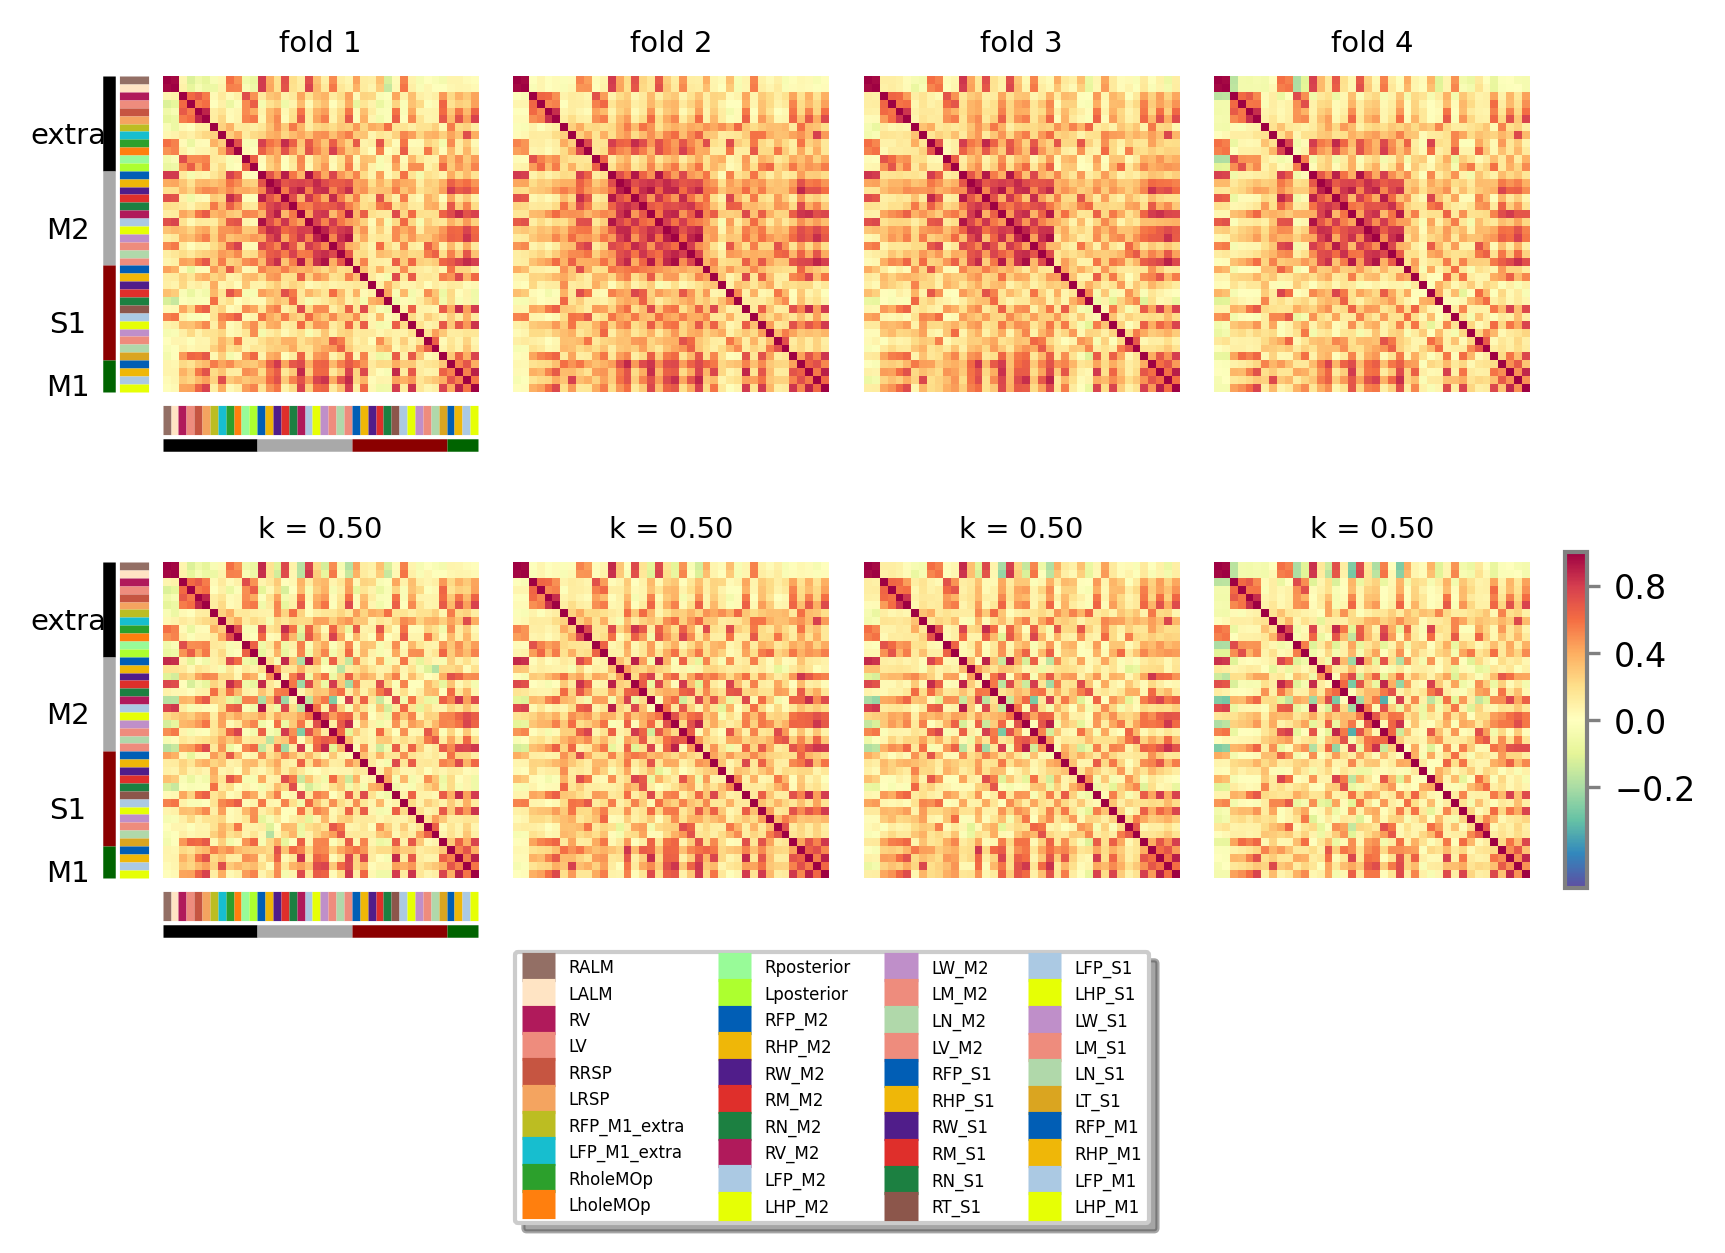

In [44]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5
for i_ax in range(4): 
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.axis('off')".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
y_start = y_offset+7; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5  
for i_ax in range(4,4+4): 
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.axis('off')".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
ax99 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop-4])
    
divnorm=colors.TwoSlopeNorm(vmin=-0.5, vcenter=0., vmax=1) 
for i_fold in range(4):
    exec("sbp0 = ax{}.imshow(dict_corrmaps_raw_4folds[i_fold] ,cmap='Spectral_r',norm=divnorm)".format(i_fold))
    
    
for i_fold,i_ax in enumerate(range(4,4+4)):
    exec("sbp0 = ax{}.imshow(dict_corrmaps_optimized_4folds[i_fold] ,cmap='Spectral_r',norm=divnorm)".format(i_ax))
    


cb = fig.colorbar(sbp0, ticks=[-0.2,0,0.4,0.8],cax=ax99,orientation='vertical')
cb.ax.tick_params(labelsize=8,length=3,color='gray')
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
ax99.set_aspect(15)
ax99.set_anchor('W')
# ax0.axis('off')


for i_count, i_ax in enumerate([0,4]):

    exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
    exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))
    start=-0.5;
    for bdp in all_bdps:
        stop = start + 1
        if i_count==0:
            ax2.plot([start,stop],[-0.09,-0.09], color=dict_all_bdps_for_color[bdp],
                    transform=trans_x,linewidth=7, clip_on=False,solid_capstyle='butt',label=bdp)
        else:
            ax2.plot([start,stop],[-0.09,-0.09], color=dict_all_bdps_for_color[bdp],
                transform=trans_x,linewidth=7, clip_on=False,solid_capstyle='butt')
        ax2.plot([-.09,-.09],[start,stop], color=dict_all_bdps_for_color[bdp],
                transform=trans_y,linewidth=7, clip_on=False,solid_capstyle='butt')
        # ax2.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
        # if i_ax_temp == 0:
        #     ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")
        start = stop



    start=-0.5;  
    # segregate area (extra, M2, S1, M1)
    for i_area,area in enumerate(['all_bdps_extra' ,'all_bdps_M2', 'all_bdps_S1', 'all_bdps_M1']):
        exec("stop = start + len({})".format(area))
        ax2.plot([start,stop],[-0.17,-0.17], color=dict_area_color[area.split('_')[-1]],
                transform=trans_x,linewidth=3, clip_on=False,solid_capstyle='butt')
        ax2.plot([-.17,-.17],[start,stop], color=dict_area_color[area.split('_')[-1]],
                transform=trans_y,linewidth=3, clip_on=False,solid_capstyle='butt')
        ax2.annotate(area.split('_')[-1], xy=(-.3,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")

        start = stop
        
ax2.legend(loc='upper center', bbox_to_anchor=(-0.1, -1.75),
              ncol=4, fontsize=4,fancybox=True, shadow=True)
plt.subplots_adjust(wspace=1)

for i_fold in range(4):
    exec("ax{}.set_title('fold {}',fontsize=7)".format(i_fold,i_fold+1))
         
        
for i_fold,i_ax in enumerate(range(4,4+4)):
    # optimal_k = dict_optimal_k[i_fold]
    exec("ax{}.set_title('k = {:0.2f}',fontsize=7)".format(i_ax,0.5))
         
         
plt.savefig('fig-SE-corr-maps-optimized_4folds_{}.svg'.format(mouse),format='svg',dpi=300)

# residual

In [56]:
optimal_k = 0.5
H_ROI = TCs_matrix
# H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
median_M2_tc = np.median(H_ROI[index_M2s,:],0)
full_jrgeco_reshape = MM_jrgeco_reshape[mask_reshape==1]

start = time.time()
temp = Parallel(n_jobs=30)(delayed(nnls_optimization_with_constraints)(
    W_S1M2M1, 
    full_jrgeco_reshape[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],median_M2_tc[i_t],index_M2s,optimal_k)) for i_t in range(full_jrgeco_reshape.shape[1]))
H_fitted = np.vstack(temp).T
non_nan_ind = ~np.isnan(H_fitted[0,:])
H_fitted = H_fitted[:,non_nan_ind].copy()
end = time.time()
print(end - start)

566.2063410282135


In [57]:
recon = np.dot(W_S1M2M1,H_fitted)

In [55]:
MM_jrgeco_reshape.shape

(65536, 6120)

(-0.5, 255.5, 255.5, -0.5)

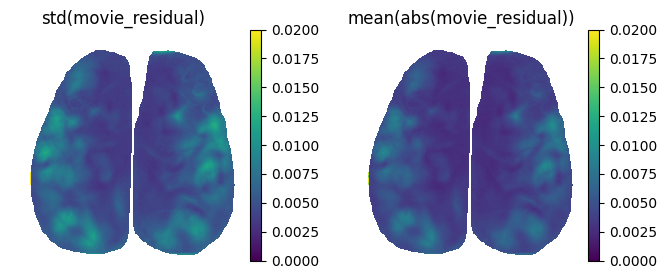

In [58]:
MM_jrgeco_reshape_here = MM_jrgeco_reshape[:,non_nan_ind]
ss= MM_jrgeco_reshape_here.shape
movie_MM_jrgeco_reshape = MM_jrgeco_reshape_here.reshape((256,256,ss[1]))

movie_recon = np.zeros_like(MM_jrgeco_reshape_here);movie_recon[:]= np.nan
movie_recon[mask_reshape==1] = recon
movie_recon = movie_recon.reshape((256,256,ss[1]))

movie_residual = movie_MM_jrgeco_reshape - movie_recon

mean_map = np.mean(np.abs(movie_residual),-1)
std_map = np.std(movie_residual,-1)

plt.figure(figsize=(8,3))
plt.subplot(121)
plt.imshow(std_map,vmin=0,vmax=0.02)
plt.colorbar()


plt.title('std(movie_residual)')
plt.axis('off')
plt.subplot(122)
plt.imshow(mean_map,vmin=0,vmax=0.02)
plt.colorbar()
plt.title('mean(abs(movie_residual))')
plt.axis('off')

# final k

In [133]:
final_k = np.mean([dict_optimal_k[i_fold] for i_fold in range(4)])
print(final_k)

0.4827586206896552


In [60]:
final_k = 0.5

In [61]:
save_root =  str(PREPARES / "CLS") + "/"

save_dict = {'full_M':full_M,
             # 'full_M_back_in_shape':full_M_back_in_shape,
            # 'full_nnls_spatial':full_nnls_spatial,
             'index_M2s':index_M2s,
             'W_S1M2M1':W_S1M2M1,
             'mask':mask,
             'TCs_matrix':TCs_matrix,
             'all_bdps_w_order_nnls':all_bdps,
             # 'mask_M2':mask_M2,
             'all_bdps_w_order':all_bdps,    
             'final_k':final_k,
             'residual_map':std_map,
            }

save_pickle(save_dict,save_root+'M2S1M1_NNLS_spatial_'+mouse)

